In [1]:
import pandas as pd
import numpy as np
import os
from MultiAgent_DQ import *
import matplotlib.pyplot as plt

In [2]:
nonconv_df = pd.read_csv('algorithm_results_comparison_non_conv.csv')

In [3]:
exp = 1

In [ ]:
M_value = nonconv_df.iloc[exp][1]
alpha = nonconv_df.iloc[exp][2]
lambda_ = nonconv_df.iloc[exp][3]
eps = nonconv_df.iloc[exp][4]
delta = nonconv_df.iloc[exp][5]
random_uniform = nonconv_df.iloc[exp][6]
print('M:', M_value, 'alpha:', alpha, 'lambda:', lambda_, 'eps:', eps, 'delta:', delta, 'random_uniform:', random_uniform)

/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_7005/2104362513.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  M_value = nonconv_df.iloc[exp][1]
/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_7005/2104362513.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  alpha = nonconv_df.iloc[exp][2]
/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_7005/2104362513.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.il

In [ ]:
algo = Algorithm(
        e=eps, lambda_val=lambda_, alpha=alpha, delta=delta,
        random_uniform=random_uniform, tolerance=1e-5, 
        M=int(M_value), verbose=False
    )
q1_history_per_sample_algo, q2_history_per_sample_algo, batch_times_algo, timeout_out, timeout_vi = algo.run()    

In [ ]:
q1 = convert_dict_to_mean_df(q1_history_per_sample_algo, mean=False)[1]
q2 = convert_dict_to_mean_df(q2_history_per_sample_algo, mean=False)[1]

In [ ]:
q1['StateC'] = q1['Q1'] - q1['Q3']
q1['StateD'] = q1['Q2'] - q1['Q4']
q2['StateC'] = q2['Q1'] - q2['Q3']
q2['StateD'] = q2['Q2'] - q2['Q4']

In [ ]:
x = q1['StateC'].values
y = q2['StateC'].values

In [ ]:
def trajectory_dinamics_plot(x, y, zoom_range=None):
    """
    zoom_range = {'xlim': (x_min, x_max), 'ylim': (y_min, y_max)}
    """
    u = x[1:] - x[:-1]
    v = y[1:] - y[:-1]

    plt.figure(figsize=(10, 10))
    plt.quiver(x[:-1], y[:-1], u, v, angles='xy', scale_units='xy', scale=1, color='grey')
    plt.scatter(x, y, color='black', s=10)
    plt.title("Trajectory Dynamics")
    plt.grid(True)

    # Apply zoom if specified
    if zoom_range is not None:
        if 'xlim' in zoom_range:
            plt.xlim(zoom_range['xlim'])
        if 'ylim' in zoom_range:
            plt.ylim(zoom_range['ylim'])

    plt.xlabel("x")
    plt.ylabel("y")
    plt.show()

def multi_centered_trajectory_plot(*trajectories, labels=None, colors=None):
    import matplotlib.pyplot as plt
    import numpy as np

    fig, ax = plt.subplots(figsize=(8, 8))

    # Set default colors if not provided
    default_colors = ['crimson', 'teal', 'orange', 'blue', 'green', 'magenta', 'brown', 'slategray']
    if colors is None:
        colors = default_colors
    if labels is None:
        labels = [f'Trajectory {i+1}' for i in range(len(trajectories))]

    # Determine max range for auto-scaling
    all_x = np.concatenate([traj[0] for traj in trajectories])
    all_y = np.concatenate([traj[1] for traj in trajectories])
    max_val = max(np.max(np.abs(all_x)), np.max(np.abs(all_y)))
    ax.set_xlim(-max_val, max_val)
    ax.set_ylim(-max_val, max_val)

    # Grid and axes setup
    ax.set_xticks(np.arange(-max_val*1.1, max_val*1.1, 1))
    ax.set_yticks(np.arange(-max_val*1.1, max_val*1.1, 1))
    ax.grid(True, which='both', linestyle='--', linewidth=0.5, color='grey', alpha=0.1)
    ax.axhline(0, color='black', linewidth=1)
    ax.axvline(0, color='black', linewidth=1)

    # Hide spines
    for spine in ['top', 'right', 'left', 'bottom']:
        ax.spines[spine].set_visible(False)

    # Axis arrows
    ax.annotate('', xy=(1, 0), xytext=(0, 0),
                arrowprops=dict(facecolor='purple', width=1.5, headwidth=8))
    ax.annotate('', xy=(0, 1), xytext=(0, 0),
                arrowprops=dict(facecolor='purple', width=1.5, headwidth=8))

    # Plot each trajectory
    for i, (x, y) in enumerate(trajectories):
        u = x[1:] - x[:-1]
        v = y[1:] - y[:-1]
        color = colors[i % len(colors)]
        label = labels[i] if i < len(labels) else f'Trajectory {i+1}'
        
        ax.quiver(x[:-1], y[:-1], u, v, angles='xy', scale_units='xy', scale=1,
                  color=color, width=0.003, headwidth=4, headlength=6, label=label)
        ax.scatter(x, y, color=color, s=10)

    ax.set_aspect('equal')
    ax.set_xlabel('x', labelpad=10, fontsize=12)
    ax.set_ylabel('y', labelpad=10, fontsize=12)
    ax.set_title("Trajectories on Cartesian Grid", fontsize=14)
    ax.legend()
    plt.show()

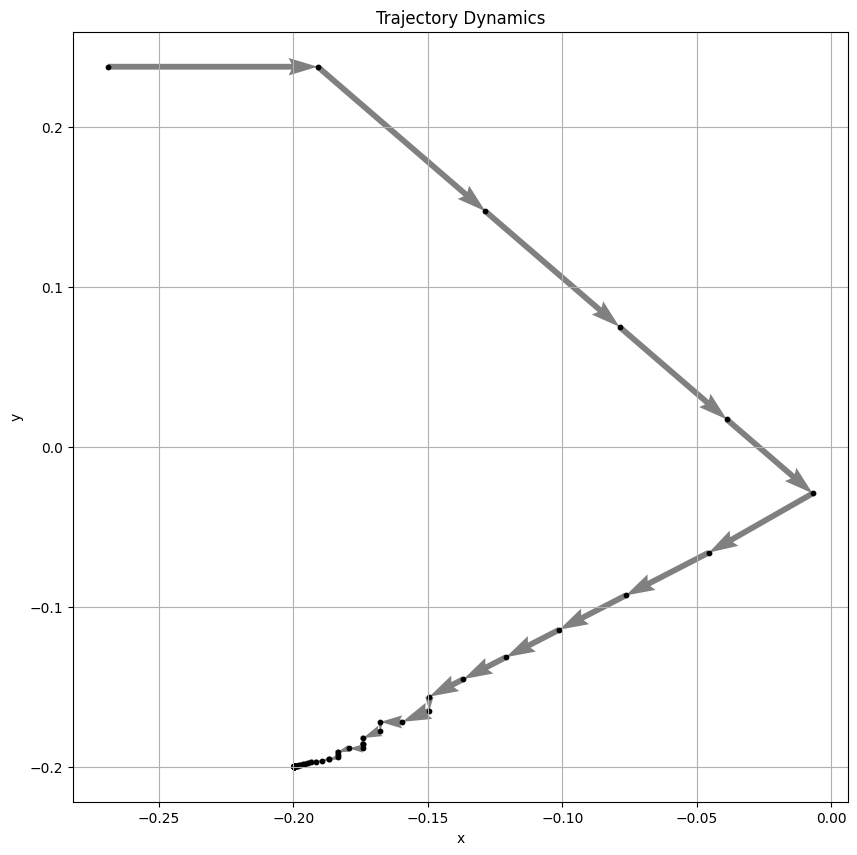

In [ ]:
trajectory_dinamics_plot(x, y)
#zr = {'xlim': (0.1, 0.13), 'ylim': (0.1, 0.2)}
#trajectory_dinamics_plot(x, y, zoom_range=zr)

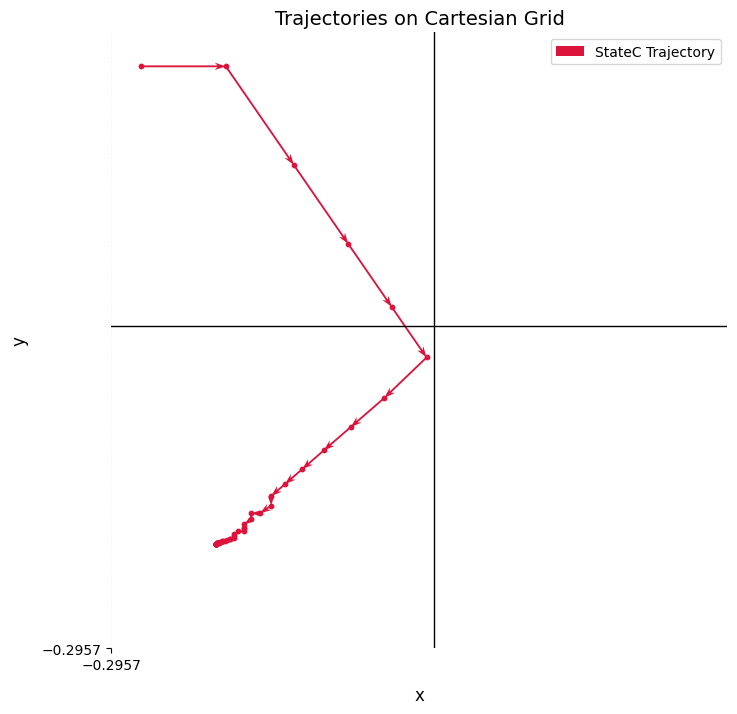

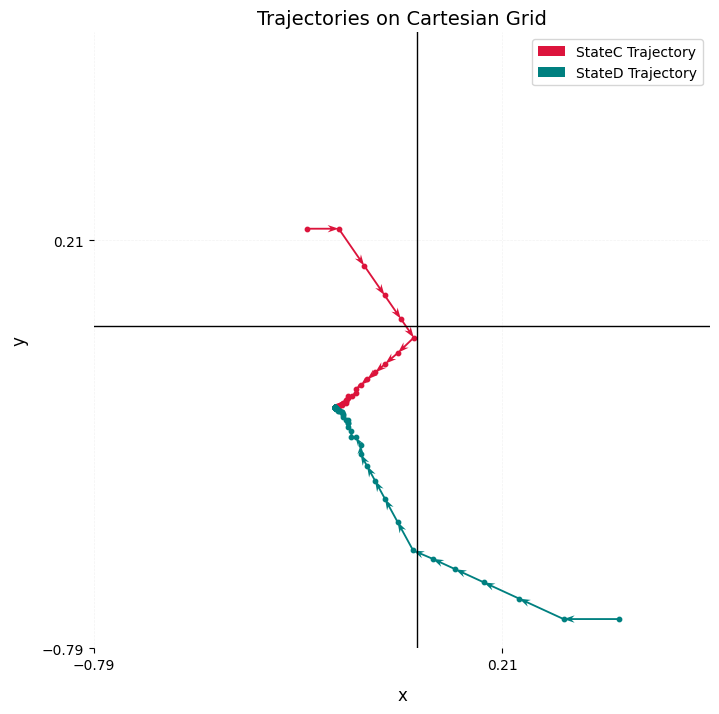

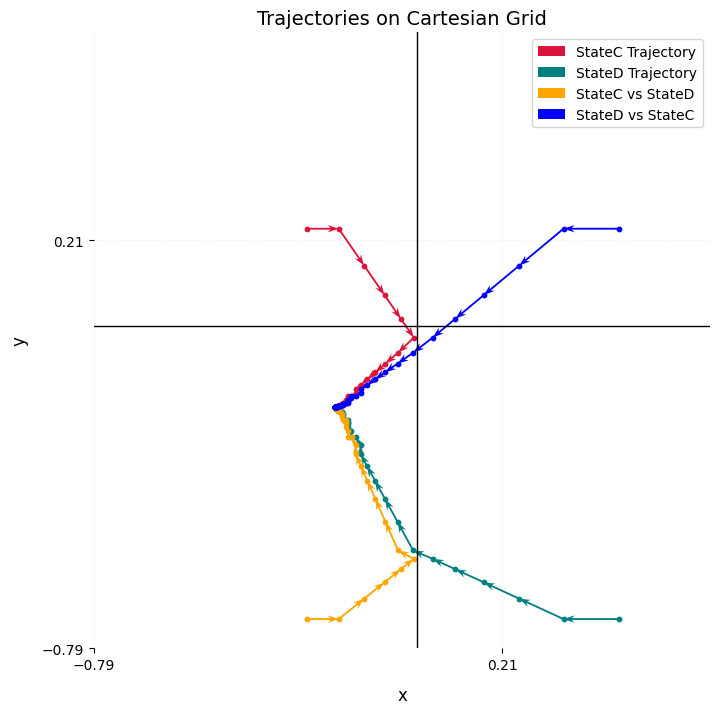

In [ ]:
multi_centered_trajectory_plot(
    (q1['StateC'].values, q2['StateC'].values),

    labels=['StateC Trajectory'],
    colors=['crimson', 'teal']
)
multi_centered_trajectory_plot(
    (q1['StateC'].values, q2['StateC'].values),
    (q1['StateD'].values, q2['StateD'].values),

    labels=['StateC Trajectory', 'StateD Trajectory'],
    colors=['crimson', 'teal', 'orange', 'blue']
)

multi_centered_trajectory_plot(
    (q1['StateC'].values, q2['StateC'].values),
    (q1['StateD'].values, q2['StateD'].values),
    (q1['StateC'].values, q2['StateD'].values),
    (q1['StateD'].values, q2['StateC'].values),

    labels=['StateC Trajectory', 'StateD Trajectory', 'StateC vs StateD', 'StateD vs StateC'],
    colors=['crimson', 'teal', 'orange', 'blue']
)
